# 02c · Does a cross-regional bottleneck cost more than a within-regional one, at matched parameters?

*Follows task 02's rank grid. Answers one question task 02's own marginals cannot: not
"which rank binds first" -- three cross blocks to one within block means cross always
binds first by counting alone -- but whether cross-region rank is a more valuable place to
spend a fixed weight count than within-region rank.*

**Why this is not task 02's dense-side marginals.** Section 1 below works the arithmetic:
holding one side fully dense and squeezing only the other cannot be made parameter-matched
in the regime that matters, so this task bottlenecks *both* sides and matches cells by
**total bottleneck dimension** (what the grid already calls ``drive_rank``, $r_w+3r_c$)
instead. Section 2 builds that matched grid; Section 3 is the only place anything new gets
trained, gated the same way task 02 gates it. Sections 4-6 read the comparison one total
bottleneck dimension at a time; Sections 7-9 pool every dimension into one paired test per
condition, region and band -- the more powerful cut, since the same five seeds recur at
every dimension and the direction of the effect turns out to be consistent across them.

| Section | |
|---|---|
| 1 | The parameter-counting problem with a dense side |
| 2 | Matching both sides: the total-bottleneck-dimension grid |
| 3 | Run state and submission (off by default) |
| 4 | Fit at matched total bottleneck dimension: worst cell and per condition |
| 5 | Does the effect depend on how much total capacity there is? |
| 6 | Which frequency band costs the most, at each total bottleneck dimension |
| 7 | Pooled across every total bottleneck dimension: the aggregate test |
| 8 | Pooled: which regions carry the effect |
| 9 | Pooled: which frequency bands carry the effect |
| 10 | Reading the result |

**Nothing here submits a job unless `SUBMIT` is set to `True`.**

In [1]:
%load_ext autoreload
%autoreload 2

from __future__ import annotations

from pathlib import Path
import sys

import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, Markdown, display

repo_root = Path.cwd()
if not (repo_root / "src").exists():
    repo_root = next(parent for parent in Path.cwd().parents if (parent / "src").exists())
if str(repo_root / "src") not in sys.path:
    sys.path.insert(0, str(repo_root / "src"))

from dal_monte_2022_analysis.config.load import load_config
from dal_monte_2022_analysis.ephys.analysis import fixation_mrnn_audit as audit
from dal_monte_2022_analysis.ephys.analysis import fixation_mrnn_protocol as protocol
from dal_monte_2022_analysis.ephys.analysis import fixation_mrnn_sweep as sweep
from dal_monte_2022_analysis.ephys.analysis import fixation_psth_noise_ceiling as ceiling_mod
from dal_monte_2022_analysis.ephys.plotting import fixation_mrnn_audit as aviz
from dal_monte_2022_analysis.ephys.plotting.thesis_common import (
    ThesisFigureSettings, apply_thesis_plot_style, figure_to_png_bytes, save_thesis_figure,
)

DATASET_CFG_PATH = repo_root / "configs" / "dataset.yaml"
MRNN_CFG_PATH = repo_root / "configs" / "ephys_fixation_mrnn.yaml"
apply_thesis_plot_style(load_config(repo_root / "configs" / "plotting.yaml"))

TREE = "final"
# Same root as task 02: these are more cells of the same rank grid, not a new sweep tree.
TASK_ROOT = sweep.resolve_task_root("02_rank_grid", DATASET_CFG_PATH, tree=TREE)
LADDER_ROOT = sweep.resolve_task_root("01_ladder", DATASET_CFG_PATH, tree=TREE)
CEILING_DIR = ceiling_mod.resolve_output_dir(DATASET_CFG_PATH)
FIGURE_DIR = TASK_ROOT.parent.parent / "plots" / "final_02c_within_vs_cross_bottleneck"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
FIGURES = ThesisFigureSettings(output_dir=FIGURE_DIR)
TABLE_DIR = TASK_ROOT.parent / "02c_within_vs_cross_bottleneck" / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)

SELECTED_PROTOCOL, PROTOCOL_IS_PROVISIONAL = sweep.load_selected_protocol_or_provisional(
    protocol.resolve_chapter_root(DATASET_CFG_PATH, task="00_training_protocol") / "selected_protocol.yaml")
BASE = yaml.safe_load((TASK_ROOT.parent / "base_model.yaml").read_text())
REGION_ORDER = tuple(BASE.pop("region_order"))
BASE.pop("inherited_protocol", None); BASE.pop("r2_centring", None)
HIDDEN_UNITS = int(BASE["hidden_units"])
N_REGIONS = len(REGION_ORDER)

ORIGINAL_RANKS = (1, 2, 3, 5, 10)
EXTENDED_RANKS = (1, 2, 3, 4, 5, 10)
GRID_SEEDS = 5
SEEDS = protocol.protocol_seeds(n_seeds=GRID_SEEDS)

_cell_path = TASK_ROOT.parent / "pc_space_ceiling_by_cell.csv"
if _cell_path.exists():
    _cell = pd.read_csv(_cell_path)
    ceiling_by_region = _cell[_cell["condition"] == "all"].set_index("region")["reliability"].to_dict()
    ceiling_by_cell = {(r, c): v for r, c, v in _cell[_cell["condition"] != "all"]
                       [["region", "condition", "reliability"]].itertuples(index=False)}
else:
    ceiling_by_region = (pd.read_csv(CEILING_DIR / "pc_space_ceiling.csv")
                         .groupby("region")["reliability"].mean().to_dict())
    ceiling_by_cell = None


def show(figure, stem: str) -> None:
    save_thesis_figure(figure, FIGURES, stem)
    display(Image(data=figure_to_png_bytes(figure, dpi=190)))


def cached(name: str, build):
    path = TABLE_DIR / f"{name}.csv"
    if path.exists():
        return pd.read_csv(path)
    frame = build()
    path.parent.mkdir(parents=True, exist_ok=True)
    frame.to_csv(path, index=False)
    return frame


print("task root (shared with 02):", TASK_ROOT)
print("table dir               :", TABLE_DIR)

task root (shared with 02): /gpfs/milgram/pi/chang/pg496/repositories/local_data/dal_monte_2022/analysis_outputs/ephys/modeling/fixation_mrnn/final/02_rank_grid
table dir               : /gpfs/milgram/pi/chang/pg496/repositories/local_data/dal_monte_2022/analysis_outputs/ephys/modeling/fixation_mrnn/final/02c_within_vs_cross_bottleneck/tables


## 1. The parameter-counting problem with a dense side

Every region has the same width $h=40$. A within-region block factored at rank $r_w$ costs
$2\,r_w\,h$ parameters; one per region, 4 regions: **$320\,r_w$** total. A cross-region
block factored at rank $r_c$ costs $2\,r_c\,h$; one per ordered pair, and full connectivity
on 4 regions has $4\times3=12$ ordered pairs: **$960\,r_c$** total. The ratio is exactly 3,
for any $h$ -- it is the count of other regions, not a property of the rank.

A **dense** within block is $h\times h=1600$ per region, **6400** total; a dense cross
block is $12\times1600=$ **19200** total -- three times as much, same reasoning.

So "cross bottlenecked, within dense" costs $6400+960\,r_c$ and "within bottlenecked, cross
dense" costs $320\,r_w+19200$. Matched parameter counts means

$$960\,r_c = 320\,r_w + 12800 \quad\Longleftrightarrow\quad r_c = \tfrac{r_w}{3} + 13.3,$$

which has no solution with $r_c<14$ for *any* $r_w\geq1$ -- a dense cross block alone
already outweighs a severely bottlenecked within block plus a dense within block combined.
Matching this comparison would force the cross side to sit at $r_c\approx14$-$27$, i.e.
35-70% of full rank, while the within side ranges over its whole severe-bottleneck regime:
not a fair comparison of two bottlenecks, but of a mild cross constraint against a genuine
one. There is no pair in the regime where *both* sides are actually constrained.

The cell below grounds the two block costs in measured parameter counts (not just the
formula) using :func:`sweep.count_trainable_parameters` on checkpoints already on disk, then
Section 2 drops the dense side entirely.

In [2]:
example_cells = {
    "w1_c1 (both bottlenecked)": TASK_ROOT / "w1_c1",
    "w1_cdense (cross dense)": TASK_ROOT / "w1_cdense",
    "wdense_c1 (within dense)": TASK_ROOT / "wdense_c1",
    "full (both dense)": LADDER_ROOT / "full",
}
rows = []
for label, path in example_cells.items():
    seed_dirs = audit.seed_run_dirs(path)
    if not seed_dirs:
        continue
    counts = sweep.count_trainable_parameters(seed_dirs[0])
    rows.append({"label": label, "within_region (incl. 'other')": counts["within_region"] + counts["other"],
                "inter_region": counts["inter_region"], "total_recurrent":
                counts["within_region"] + counts["other"] + counts["inter_region"]})
measured = pd.DataFrame(rows)
display(Markdown(
    "`within_region` is folded into `count_trainable_parameters`'s `other` bucket for the "
    "low-rank case (it only names the dense-branch parameter), so the two are summed here."))
display(measured)

r_c_grid = pd.DataFrame({"r_w": [1, 2, 3, 5, 10, 20]})
r_c_grid["matched r_c (cross dense side)"] = r_c_grid["r_w"] / 3 + 12800 / 960
display(Markdown("**Matched $r_c$ for 'within bottlenecked, cross dense' against 'cross "
                 "bottlenecked, within dense', by $r_w$:**"))
display(r_c_grid.round(2))

`within_region` is folded into `count_trainable_parameters`'s `other` bucket for the low-rank case (it only names the dense-branch parameter), so the two are summed here.

,label,within_region (incl. 'other'),inter_region,total_recurrent
0,w1_c1 (both bottlenecked),320,960,1280
1,w1_cdense (cross dense),320,19200,19520
2,wdense_c1 (within dense),6400,960,7360
3,full (both dense),6400,19200,25600


**Matched $r_c$ for 'within bottlenecked, cross dense' against 'cross bottlenecked, within dense', by $r_w$:**

,r_w,matched r_c (cross dense side)
0,1,13.67
1,2,14.00
2,3,14.33
3,5,15.00
4,10,16.67
5,20,20.00


## 2. Matching both sides: the total-bottleneck-dimension grid

No dense arm. Every configuration bottlenecks within at $r_w$ and cross at $r_c$; its
**total bottleneck dimension** is $r_w + 3\,r_c$ -- the same quantity task 02's own
marginals plot calls ``drive_rank``, the bound on a region's pre-activation rank -- and is
proportional to its total recurrent-weight count (the fixed $320$-per-unit scale cancels in
any comparison). Two configurations sharing it spend it differently -- more on within, more
on cross -- which is the matched comparison this task runs. `cross_drive_fraction` is the
share spent cross-region: 0 is all within, 1 is all cross.

Task 02's grid used $r\in\{1,2,3,5,10\}$; adding **$r=4$** closes enough of the gap to
match every configuration already on disk against a genuine opposite-heavy partner at the
same total bottleneck dimension, without a wide new rank sweep. Dimensions reached by three
configurations (13 and 16, below) also show the interior point for context, though the
paired contrast in Sections 4-6 only ever uses the two extremes -- the largest
within-vs-cross contrast that total allows.

In [3]:
groups = audit.matched_drive_rank_groups(EXTENDED_RANKS, n_regions=N_REGIONS)
extremes = audit.matched_drive_rank_extremes(groups)

existing_labels = {f"w{w}_c{c}" for w in ORIGINAL_RANKS for c in ORIGINAL_RANKS}
groups["already_trained"] = groups["label"].isin(existing_labels)
display(Markdown(f"**{len(groups)} matched configurations across {groups['drive_rank'].nunique()} "
                 f"total-bottleneck-dimension levels** ({int(groups['already_trained'].sum())} already "
                 f"on disk from task 02, {int((~groups['already_trained']).sum())} new at rank 4)."))
display(groups[["drive_rank", "label", "rank_within", "rank_cross", "cross_drive_fraction", "already_trained"]]
       .sort_values(["drive_rank", "cross_drive_fraction"]))

display(Markdown("**The paired extremes used in Sections 4-6:**"))
display(extremes)

needed_labels = sorted(set(extremes["within_heavy_label"]) | set(extremes["cross_heavy_label"]))
new_labels = [l for l in needed_labels if l not in existing_labels]
display(Markdown(f"**New training required:** {len(new_labels)} configurations x {GRID_SEEDS} "
                 f"seeds = {len(new_labels) * GRID_SEEDS} runs -- {', '.join(new_labels)}."))

**20 matched configurations across 9 total-bottleneck-dimension levels** (12 already on disk from task 02, 8 new at rank 4).

,drive_rank,label,rank_within,rank_cross,cross_drive_fraction,already_trained
0,7,w4_c1,4,1,0.428571,False
1,7,w1_c2,1,2,0.857143,True
2,8,w5_c1,5,1,0.375000,True
3,8,w2_c2,2,2,0.750000,True
4,10,w4_c2,4,2,0.600000,False
5,10,w1_c3,1,3,0.900000,True
6,11,w5_c2,5,2,0.545455,True
7,11,w2_c3,2,3,0.818182,True
8,13,w10_c1,10,1,0.230769,True
9,13,w4_c3,4,3,0.692308,False


**The paired extremes used in Sections 4-6:**

,drive_rank,within_heavy_label,within_heavy_rank_within,within_heavy_rank_cross,cross_heavy_label,cross_heavy_rank_within,cross_heavy_rank_cross
0,7,w4_c1,4,1,w1_c2,1,2
1,8,w5_c1,5,1,w2_c2,2,2
2,10,w4_c2,4,2,w1_c3,1,3
3,11,w5_c2,5,2,w2_c3,2,3
4,13,w10_c1,10,1,w1_c4,1,4
5,14,w5_c3,5,3,w2_c4,2,4
6,16,w10_c2,10,2,w1_c5,1,5
7,17,w5_c4,5,4,w2_c5,2,5
8,19,w10_c3,10,3,w4_c5,4,5


**New training required:** 6 configurations x 5 seeds = 30 runs -- w1_c4, w2_c4, w4_c1, w4_c2, w4_c5, w5_c4.

## 3. Run state and submission

Only the `new_labels` configurations from Section 2 -- the rest of the extended grid is
already on disk. Same gate as task 02: nothing is queued unless `SUBMIT` is set to `True`
and this cell is rerun.

In [4]:
def _variant_for(label: str):
    r_w, r_c = label.removeprefix("w").split("_c")
    variants = audit.rank_grid_variants((int(r_w), int(r_c)), base_overrides=BASE, include_marginals=False)
    return next(v for v in variants if v.label == label)

new_variants = [_variant_for(label) for label in new_labels]

SUBMIT = False   # <-- set to True to queue every missing run as one array

flight = sweep.in_flight_run_dirs(TASK_ROOT / "_jobs")
commands, _ = sweep.variant_job_commands(
    new_variants, SEEDS, root=TASK_ROOT, repo_root=repo_root,
    protocol=SELECTED_PROTOCOL, mrnn_cfg_path=MRNN_CFG_PATH, exclude_run_dirs=flight["run_dirs"])
inventory = sweep.index_variant_runs(TASK_ROOT, new_variants, SEEDS, in_flight=flight["run_dirs"])
display(Markdown(
    f"**{int(inventory['complete'].sum())} complete**, **{int(inventory['queued'].sum())} queued**, "
    f"**{int(inventory['pending'].sum())} unqueued** of {len(inventory)} new-configuration runs."))

if SUBMIT and commands:
    from datetime import datetime
    from dal_monte_2022_analysis.runtime.hpc.jobs import submit_dsq_array_job, write_job_file

    jobs_dir = TASK_ROOT / "_jobs"
    jobs_dir.mkdir(parents=True, exist_ok=True)
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    job_file = jobs_dir / f"within_vs_cross_{stamp}.txt"
    write_job_file(job_file, commands)
    submitted = [Path(line.split("--run-dir ")[1].split()[0]) for line in commands]
    job_id = submit_dsq_array_job(
        job_file_path=job_file, sbatch_script_path=jobs_dir / f"within_vs_cross_{stamp}.sh",
        log_dir=jobs_dir / "logs", job_name="mrnn_within_vs_cross", partition="psych_gpu",
        cpus_per_task=1, mem_per_cpu="12G", time_limit="06:00:00", gres="gpu:1",
    )
    sweep.record_submission(jobs_dir, job_id=job_id, run_dirs=submitted, label=f"within vs cross {stamp}")
    (jobs_dir / "job_id.txt").write_text(str(job_id) + "\n")
    display(Markdown(f"Submitted **{len(commands)}** runs as array **{job_id}**."))
elif commands:
    display(Markdown("`SUBMIT` is **False** -- nothing was submitted."))
else:
    display(Markdown("Every matched configuration is trained."))

**30 complete**, **0 queued**, **0 unqueued** of 30 new-configuration runs.

Every matched configuration is trained.

## 4. Fit at matched total bottleneck dimension: worst cell and per condition

All configurations in Section 2's grid, trained or not, so the panels below fill in as
Section 3's runs complete. Each violin is within-heavy or cross-heavy at one total
bottleneck dimension, drawn from every seed x region point (``worst_cell`` only has seeds,
since it is already the minimum over region x condition); brackets mark the total-bottleneck
dimensions the Holm correction leaves significant, paired by seed. `worst_cell` is the
minimax objective's own quantity; `all_conditions` is the mean over fixation types this
chapter often reports beside the per-condition breakdown; the three condition panels use
that fixation type's standard colour, with cross-heavy hatched.

**155** of **180** extended-grid runs complete.

**4** of **45** (dimension x condition) cells Holm-significant on their own -- Section 7 pools across dimension for more power.

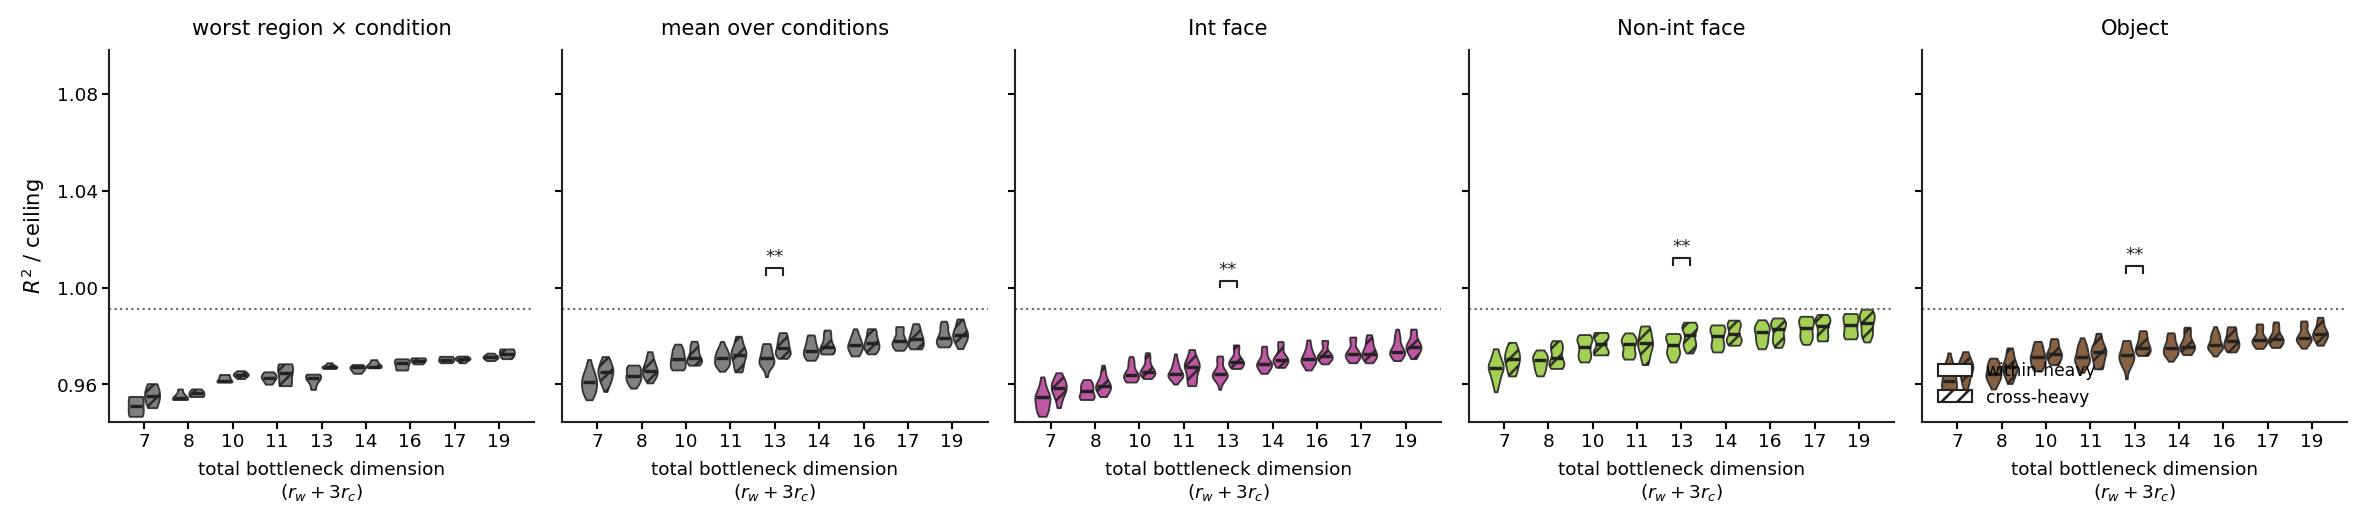

In [5]:
all_variants = audit.rank_grid_variants(EXTENDED_RANKS, base_overrides=BASE, include_marginals=False)
all_inventory = sweep.index_variant_runs(TASK_ROOT, all_variants, SEEDS)
done = all_inventory[all_inventory["complete"]]
display(Markdown(f"**{int(done.shape[0])}** of **{all_inventory.shape[0]}** extended-grid runs complete."))

if done.empty:
    fit = fit_long = fit_contrast = None
else:
    fit = cached("extended_grid_fit", lambda: sweep.score_variant_fit(done, ceiling_by_region, ceiling_by_cell=ceiling_by_cell))
    fit_long = audit.matched_drive_rank_fit_long(fit, extremes)
    fit_contrast = audit.matched_drive_rank_fit_contrast(fit_long)
    display(Markdown(f"**{int(fit_contrast['significant'].sum())}** of **{len(fit_contrast)}** "
                     "(dimension x condition) cells Holm-significant on their own -- Section 7 "
                     "pools across dimension for more power."))

    full_dirs = audit.seed_run_dirs(LADDER_ROOT / "full")
    dense_value = None
    if full_dirs:
        full_inv = pd.DataFrame([{"label": "full", "seed": p.name.replace("seed=", ""), "run_dir": str(p),
                                  "complete": True} for p in full_dirs])
        full_fit = sweep.score_variant_fit(full_inv, ceiling_by_region, ceiling_by_cell=ceiling_by_cell)
        dense_value = float(full_fit.groupby("seed")["r2_vs_ceiling"].min().mean())

    show(aviz.plot_drive_rank_contrast(fit_long, fit_contrast, dense_value=dense_value), "fig01_drive_rank_contrast")

## 5. Does the effect depend on how much total capacity there is?

Section 4's `cross_minus_within` against total bottleneck dimension, one line per fixation
type (`worst_cell` and `all_conditions` neutral, the three fixation types in their standard
colour). A flat line is a fixed per-parameter advantage to spending on cross rather than
within, wherever the total sits; a line trending toward zero says the allocation only
matters when capacity is scarce overall. Holm-significant dimensions (Section 4) are ringed.

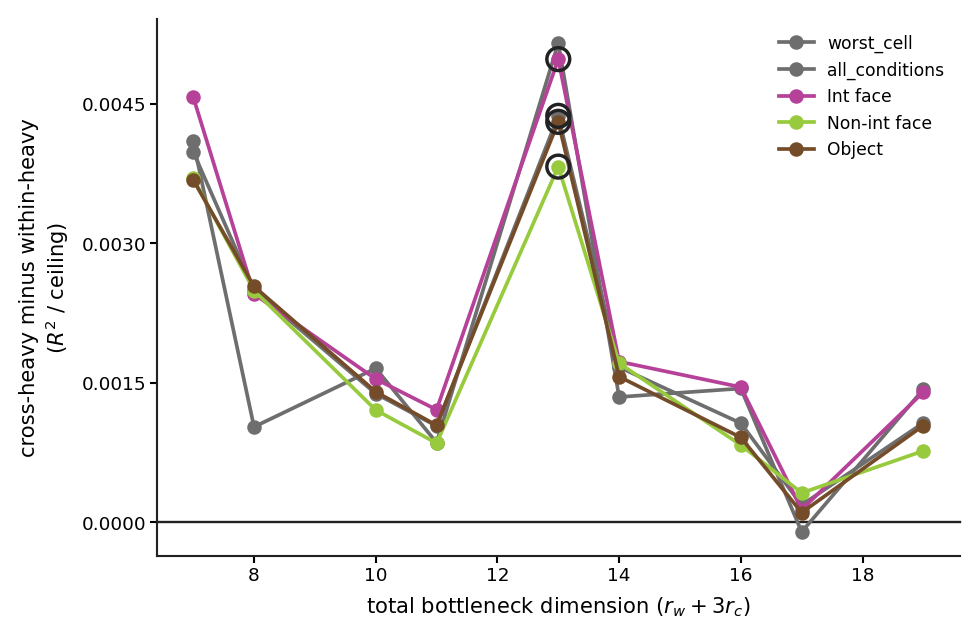

In [6]:
if fit_contrast is not None and not fit_contrast.empty:
    show(aviz.plot_drive_rank_trend(
        fit_contrast, conditions=("worst_cell", "all_conditions", "face_interactive",
                                   "face_non_interactive", "object")),
        "fig03_drive_rank_trend")

## 6. Which frequency band costs the most, at each total bottleneck dimension

Per-condition, per-band residual fraction (target power the fit fails to reproduce),
contrasted the same way: within-heavy vs. cross-heavy violins at matched total bottleneck
dimension, one row per fixation type in its standard colour, one column per band. Bands
follow the ladder's own split (Nyquist 50 Hz at 10 ms bins); `band_resolved_recovery_by_condition`
is the per-condition counterpart of the function the ladder notebook already uses pooled over
condition. Each band column has its own y-scale (bands differ by an order of magnitude in
how well they are reproduced), fixed once every panel in that column is drawn.

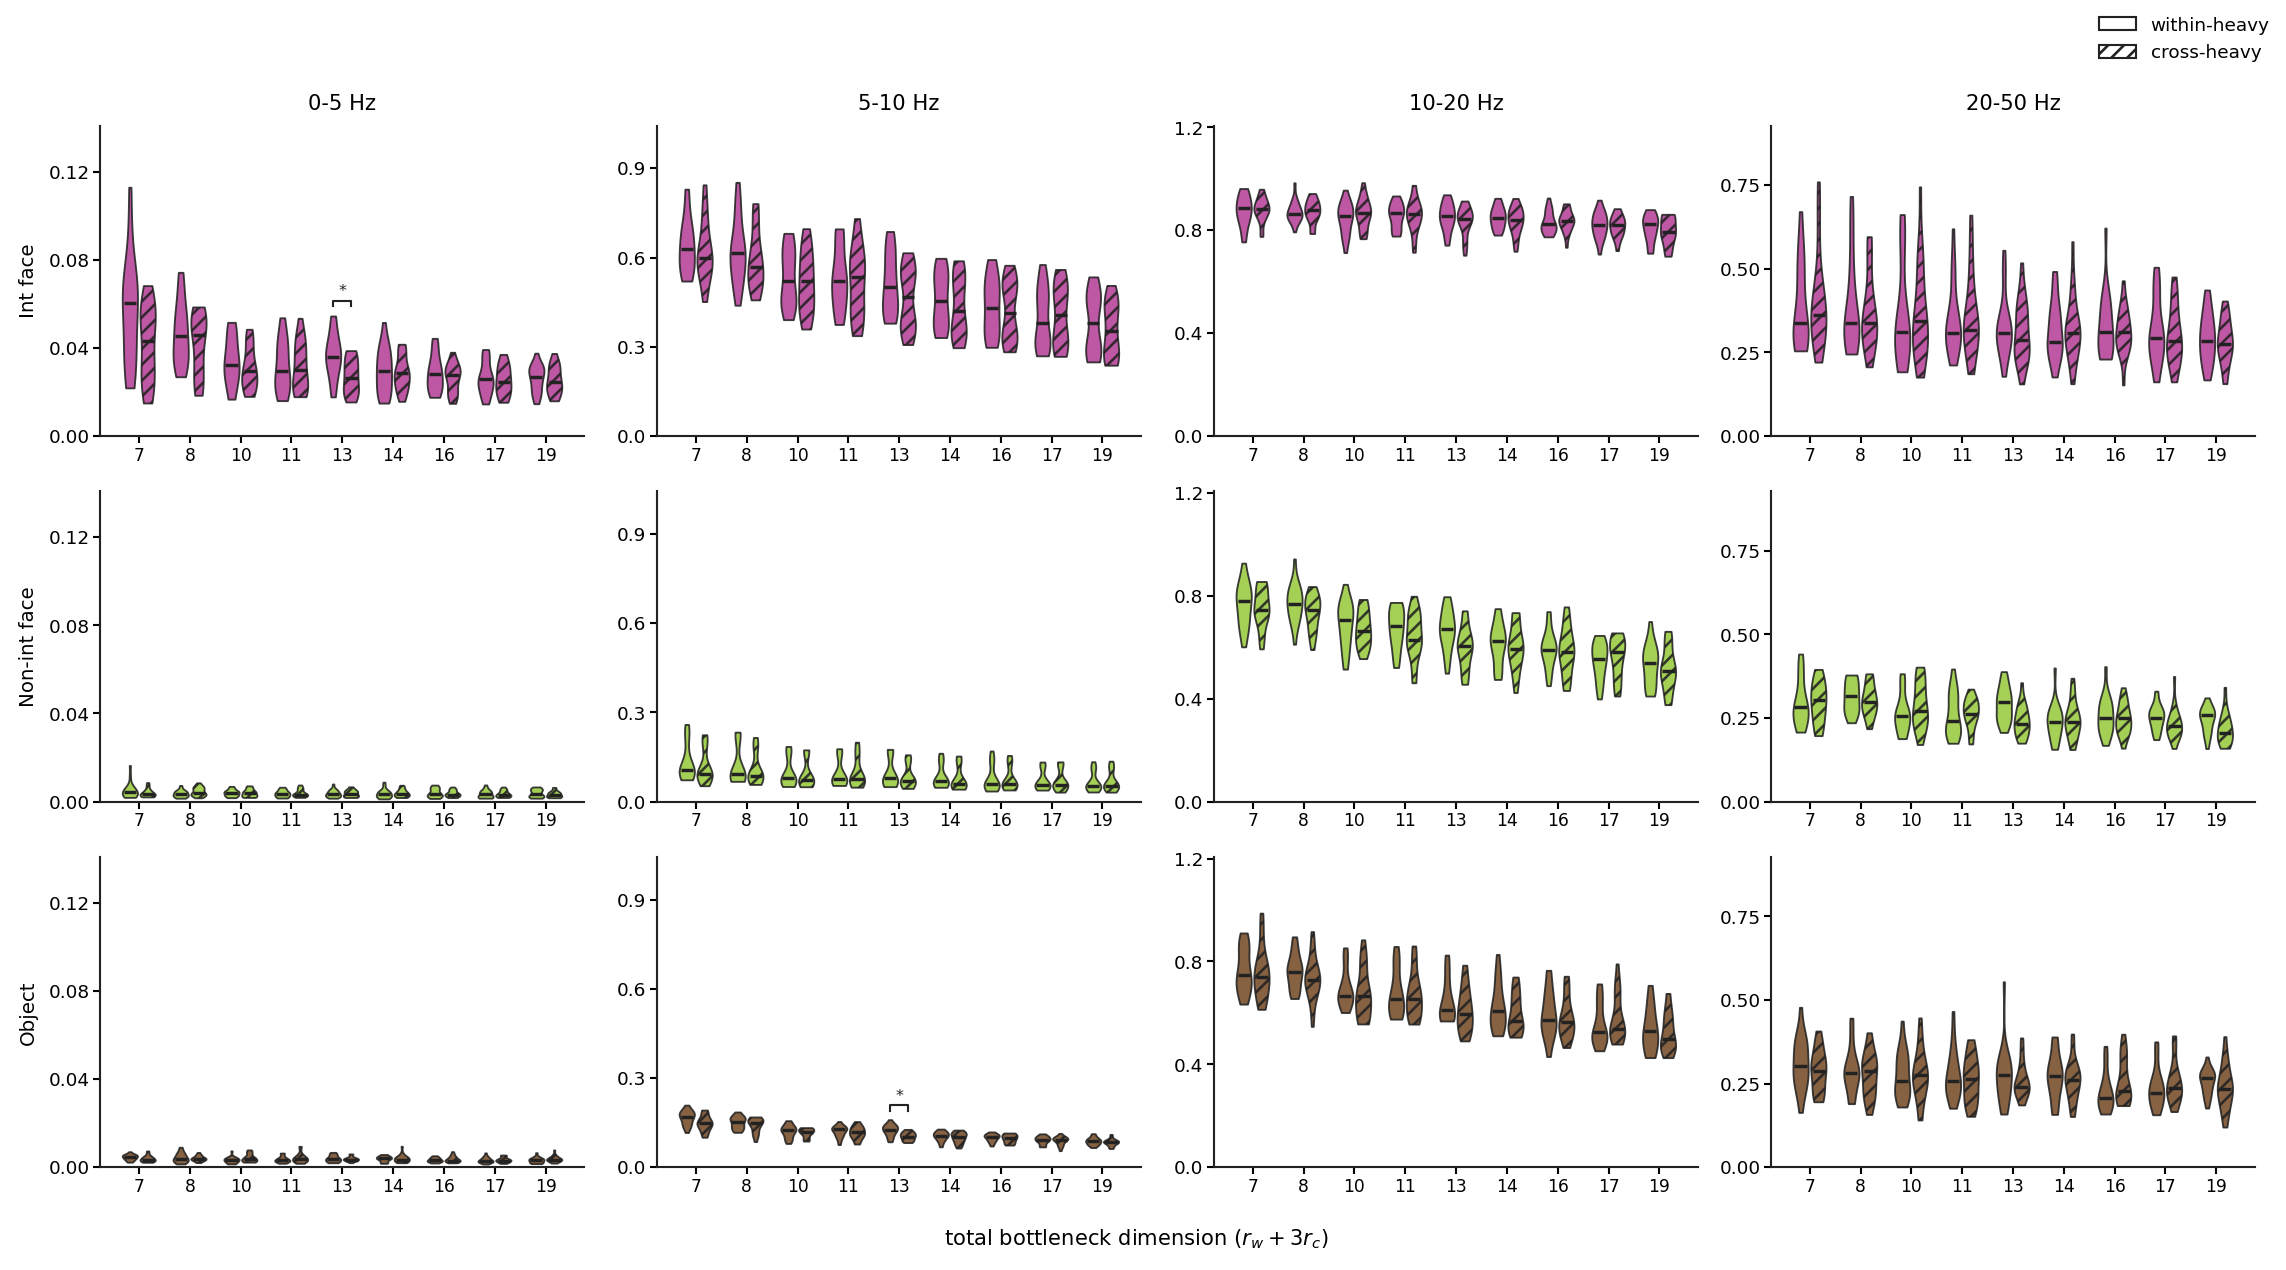

In [7]:
if done.empty:
    band_long = band_contrast = None
else:
    band_by_condition = cached("band_recovery_by_condition", lambda: pd.concat(
        [audit.band_resolved_recovery_by_condition(r.run_dir).assign(label=r.label) for r in done.itertuples()],
        ignore_index=True))
    band_long = audit.matched_drive_rank_band_long(band_by_condition, extremes)
    band_contrast = audit.matched_drive_rank_band_contrast(band_long)
    show(aviz.plot_drive_rank_band_contrast(band_long, band_contrast), "fig04_drive_rank_band_contrast")

## 7. Pooled across every total bottleneck dimension: the aggregate test

Sections 4-6 are nine separate paired tests, one per total bottleneck dimension,
Holm-corrected against each other -- the right question when asking whether any single
matched pair clears significance on its own, but it throws away that the same five seeds
recur at every dimension and that the sign of the effect barely changes across them.
Treating **(total bottleneck dimension, seed)** as the paired replicate is still a paired
test -- within-heavy and cross-heavy at one dimension are the same seed, just a different
split of the same total -- and gives 9 x 5 = 45 pairs per condition instead of 5.
`matched_drive_rank_fit_pooled` runs that test, a paired Cohen's $d_z$, and a two-sided sign
test: a tight p-value with a sign test near 0.5 would mean the pooled effect is driven by a
few large seeds rather than most of them agreeing, which the bars below would not show on
their own.

**5 of 5** condition categories significant after Holm correction, pooling 45 (total bottleneck dimension, seed) pairs each.

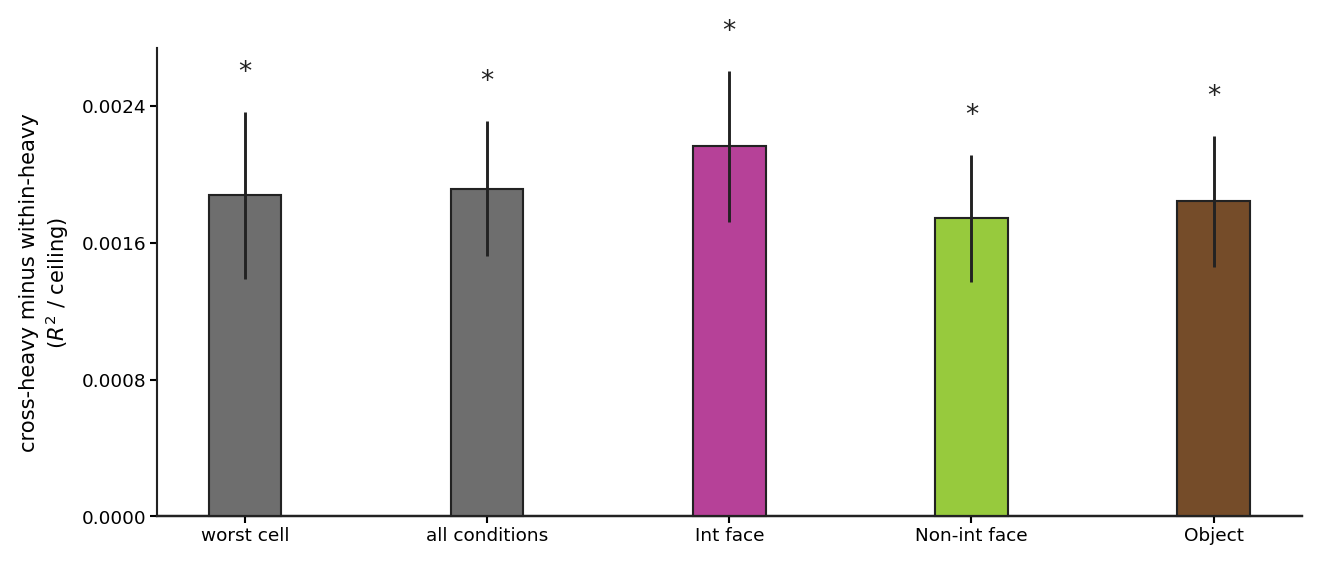

,condition,n_pairs,cross_minus_within,cohens_dz,p_holm,stars,n_positive,sign_test_p
0,all_conditions,45,0.0019,0.7223,0.0001,****,36,0.0001
1,face_interactive,45,0.0022,0.7285,0.0001,****,34,0.0008
2,face_non_interactive,45,0.0017,0.7010,0.0001,****,36,0.0001
3,object,45,0.0018,0.7165,0.0001,****,34,0.0008
4,worst_cell,45,0.0019,0.5740,0.0004,***,31,0.0161


In [8]:
if fit_long is not None:
    pooled_fit = audit.matched_drive_rank_fit_pooled(fit_long)
    n_pairs = int(pooled_fit["n_pairs"].iloc[0]) if not pooled_fit.empty else 0
    n_sig = int(pooled_fit["significant"].sum())
    display(Markdown(
        f"**{n_sig} of {len(pooled_fit)}** condition categories significant after Holm "
        f"correction, pooling {n_pairs} (total bottleneck dimension, seed) pairs each."))
    show(aviz.plot_gap_bars(
        pooled_fit, x="condition",
        x_order=["worst_cell", "all_conditions", "face_interactive", "face_non_interactive", "object"],
    ), "fig05_pooled_fit_gap_bars")
    display(pooled_fit[["condition", "n_pairs", "cross_minus_within", "cohens_dz", "p_holm", "stars",
                        "n_positive", "sign_test_p"]].round(4))

## 8. Pooled: which regions carry the effect

Same pooling as Section 7, split by region instead of averaged over it (`worst_cell` has no
region -- it is already the minimum over region x condition -- so it is not shown here).
Bars grouped by fixation type within each region; `p_holm` corrects within each fixation
type's panel across its four regions.

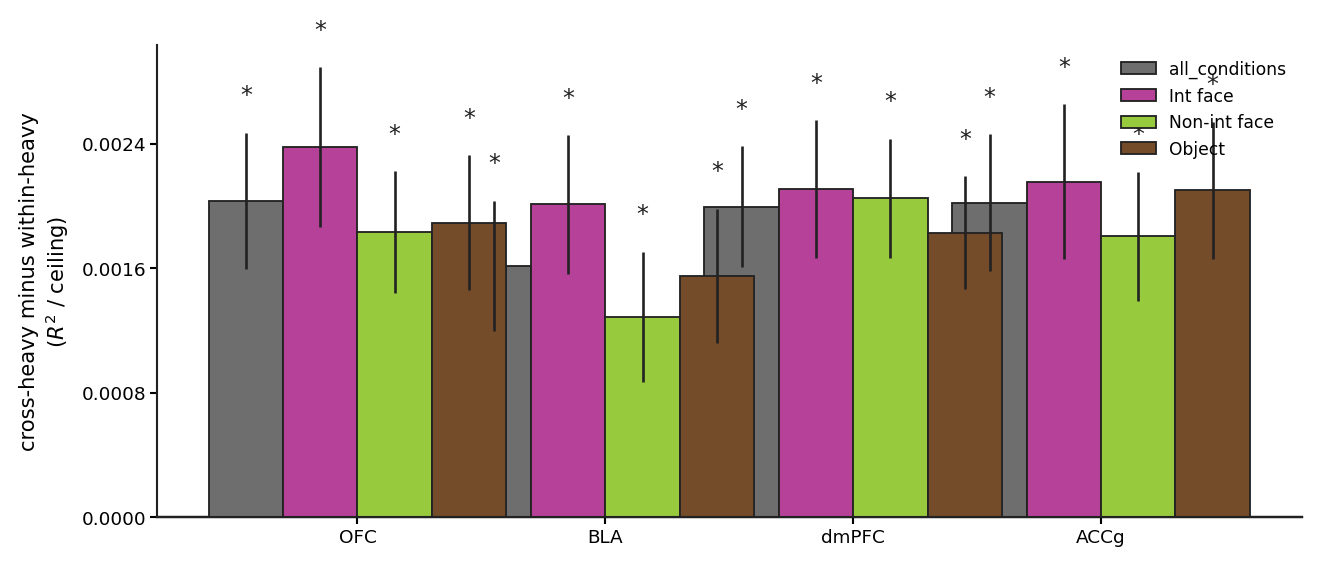

In [9]:
if fit_long is not None:
    by_region = audit.matched_drive_rank_fit_by_region(fit_long)
    show(aviz.plot_gap_bars(
        by_region, x="region", x_order=list(REGION_ORDER), hue="condition",
        hue_order=["all_conditions", "face_interactive", "face_non_interactive", "object"],
        x_labels=aviz.REGION_LABELS,
    ), "fig06_pooled_region_gap_bars")

## 9. Pooled: which frequency bands carry the effect

Same pooling, split by band instead of by total bottleneck dimension -- Section 6 condensed
from (dimension x condition x band) to (condition x band). `p_holm` corrects within each
fixation type's panel across its four bands.

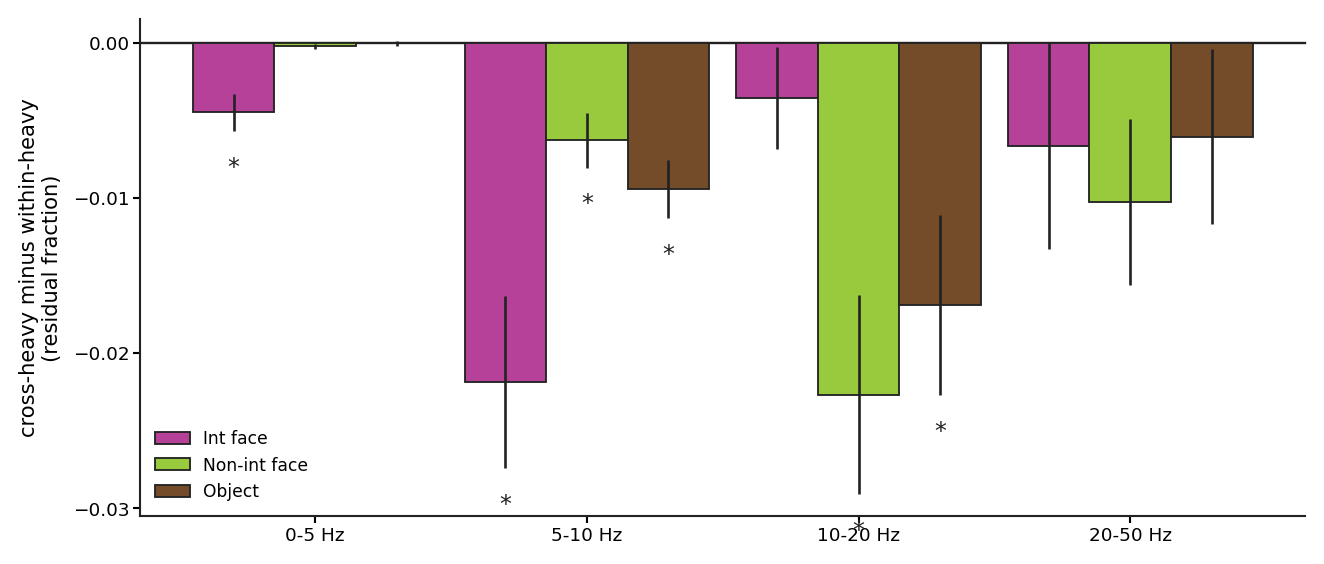

In [10]:
if band_long is not None:
    band_pooled = audit.matched_drive_rank_band_pooled(band_long)
    show(aviz.plot_gap_bars(
        band_pooled, x="band", x_order=["0-5 Hz", "5-10 Hz", "10-20 Hz", "20-50 Hz"], hue="condition",
        hue_order=["face_interactive", "face_non_interactive", "object"],
        ylabel="cross-heavy minus within-heavy\n(residual fraction)",
    ), "fig07_pooled_band_gap_bars")

## 10. Reading the result

**The headline comparison.** Sections 4 and 7: at every total bottleneck dimension tested,
and overwhelmingly significantly once pooled, **cross-heavy configurations fit at least as
well as within-heavy ones, never worse** -- the opposite of "a cross-regional bottleneck
costs more than a within-regional one". The pooled effect is small in absolute $R^2$/ceiling
terms (~0.002) but consistent (31-36 of 45 pairs the same sign per condition, sign-test
p < 0.02 throughout) and of medium size in paired-Cohen's-$d_z$ terms (0.57-0.73).

**Whether it is a fixed cost or a scarcity effect.** Section 5: the gap does not shrink
cleanly toward zero as total bottleneck dimension grows over the range tested (7-19), though
the single clearest dimension (13, the most extreme within- vs. cross-heavy split on the
grid) suggests the allocation matters most away from the symmetric middle.

**Which fixation type carries it.** Sections 7-8: all three fixation types and `all_conditions`
are significant pooled, in every one of the four regions -- not concentrated in interactive
face despite it being the hardest condition for the dense model, and not localized to one
region.

**Which frequency band carries it.** Section 9: significant in 5-10 Hz for all three fixation
types, plus 0-5 Hz for interactive face and 10-20 Hz for the other two conditions; never
significant in the fastest band (20-50 Hz) for any condition. The advantage to spending on
cross rather than within sits in slow-to-mid frequency content, not the fast structure the
dense model already struggles with.

**What this says about within vs. cross dimensionality.** The grid gives no support for
cross-region connections needing to be protected from bottlenecking more than within-region
ones; if anything, within-region rank is the one with lower marginal value here -- spending
the same parameters on cross rather than within recovers slightly more of the signal, most
reliably in the slower bands.

**If more dimensions would sharpen the claim.** Section 2/3's `new_labels` is driven entirely
by `EXTENDED_RANKS`; adding ranks 6-9 the same way extends the ladder with no change to
Sections 4-9, which read whatever :func:`matched_drive_rank_groups` finds.